# 01 - Analise explortória do Dataset ToLD-BR

Este notebook tem como objetivo caracterizar o dataset **ToLD-BR** (versão binária) e gerar as visualizações que sustentarão a seção de Análise Exploratória do trabalho.

**Pré-requisitos:**
- Ter rodado o `00_setup_colab.ipynb` (ambiente configurado).
- Ter o dataset baixado em `data/processed/told-br-binary` (via `src/load_data.py`).

## 1. Setup e Carregamento
Importação de bibliotecas, configuração do ambiente e carregamento dos dados.

In [3]:
import sys
import os
import glob
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_from_disk
from IPython.display import display

# --- CORREÇÃO DEFINITIVA (BUSCA AUTOMÁTICA) ---
# O glob procura o arquivo utils.py em qualquer subpasta do /content
arquivos_utils = glob.glob("/content/**/src/utils.py", recursive=True)

if arquivos_utils:
    # Pega o caminho onde o utils.py foi encontrado (ex: /content/repo/src/utils.py)
    caminho_utils = Path(arquivos_utils[0])
    
    # A pasta src é a pasta pai do utils.py, e a raiz é a pasta pai da src
    caminho_src = caminho_utils.parent
    raiz_projeto = caminho_src.parent
    
    # Adiciona a pasta src no path do Python
    if str(caminho_src) not in sys.path:
        sys.path.insert(0, str(caminho_src))
        
    print(f"✅ Módulo 'utils' encontrado e configurado!")
    print(f"📁 Raiz do projeto definida como: {raiz_projeto}")
else:
    print("❌ ERRO FATAL: O arquivo utils.py não foi encontrado no Colab.")
    print("⚠️ Você se esqueceu de clonar o repositório ou reiniciou o ambiente?")
    print("Rode a célula do 'git clone' novamente antes de continuar.")

# Testa o import
try:
    from utils import setup_logging, ensure_dir, save_results
    print("✅ Importação concluída com sucesso!")
except ModuleNotFoundError:
    print("❌ Ainda não foi possível importar o utils.")
    raise

# Configurações visuais
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({'font.size': 12})
logger = setup_logging(name="exploracao")

✅ Módulo 'utils' encontrado e configurado!
📁 Raiz do projeto definida como: /content/Classifica-o-de-Discurso-T-xico-em-Redes-Sociais
✅ Importação concluída com sucesso!


In [5]:
# Usa a raiz do projeto para montar o caminho absoluto do dataset
dataset_path = raiz_projeto / "data" / "processed" / "told-br-binary-clean"

if not dataset_path.exists():
    print(f"❌ O dataset não existe em: {dataset_path}")
    print("Você rodou o load_data.py e o preprocessing.py nesta sessão?")
else:
    ds = load_from_disk(str(dataset_path))
    print("✅ Dataset carregado com sucesso!")
    print(ds)

✅ Dataset carregado com sucesso!
DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'text_tfidf', 'text_bert'],
        num_rows: 16800
    })
    test: Dataset({
        features: ['text', 'label', 'text_tfidf', 'text_bert'],
        num_rows: 2100
    })
    validation: Dataset({
        features: ['text', 'label', 'text_tfidf', 'text_bert'],
        num_rows: 2100
    })
})


## 2. Visão Geral e Distribuição de Classes\n",

Verificar o tamanho de cada split (treino, validação, teste) e o balanceamento da classe alvo (`label`).

In [6]:
# Convertendo para Pandas para facilitar a análise\n",
df_train = ds['train'].to_pandas()
df_val = ds['validation'].to_pandas()
df_test = ds['test'].to_pandas()
print(f"Tamanho do Treino: {len(df_train)} amostras")
print(f"Tamanho da Validação: {len(df_val)} amostras")
print(f"Tamanho do Teste: {len(df_test)} amostras")

# Visualizando as primeiras linhas\n",
display(df_train.head())

Tamanho do Treino: 16800 amostras
Tamanho da Validação: 2100 amostras
Tamanho do Teste: 2100 amostras


,text,label,text_tfidf,text_bert
0,"rt @user olha quem chegouuuuu, nossos queridin...",0,rt olha chegouuuuu queridinhos vem direcao fem...,"rt @user olha quem chegouuuuu, nossos queridin..."
1,veio umas teorias muito loucas na minha cabeça...,1,veio umas teorias loucas cabeca agora pqp to a...,veio umas teorias muito loucas na minha cabeça...
2,@user @user 😂😂😂😂mais nao tinha falado ontem qu...,0,nao falado ontem nao ia patrocinado nada pudes...,@user @user 😂😂😂😂mais nao tinha falado ontem qu...
3,rt @user quer ser filha da puta logo comigo qu...,1,rt quer filha puta logo comigo pior kkkkkkkkkk...,rt @user quer ser filha da puta logo comigo qu...
4,vai besta 😂😂😂😂 casquei com a ultima foto,1,vai besta casquei ultima foto,vai besta 😂😂😂😂 casquei com a ultima foto


Distribuição no Treino: 
Tóxico" if label == 1 else "Não Tóxico (0): 9425 amostras (56.10%)
Tóxico" if label == 1 else "Não Tóxico (1): 7375 amostras (43.90%)


/tmp/ipykernel_12574/4128464742.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=['Não Tóxico', 'Tóxico'], y=class_counts.values, palette=['#4C72B0', '#C44E52'])


FileNotFoundError: [Errno 2] No such file or directory: '../results/figures/01_distribuicao_classes.png'

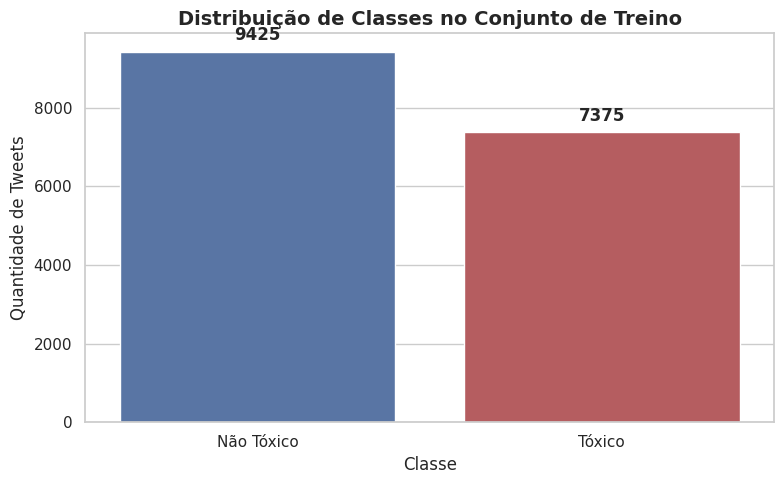

In [7]:
# Distribuição de classes (Treino)
class_counts = df_train['label'].value_counts()
class_pct = df_train['label'].value_counts(normalize=True) * 100

print("Distribuição no Treino: ")
for label, count in class_counts.items():
    nome = "Tóxico\" if label == 1 else \"Não Tóxico"
    print(f"{nome} ({label}): {count} amostras ({class_pct[label]:.2f}%)")

# Plotando o gráfico de barras
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=['Não Tóxico', 'Tóxico'], y=class_counts.values, palette=['#4C72B0', '#C44E52'])
plt.title('Distribuição de Classes no Conjunto de Treino', fontsize=14, fontweight='bold')
plt.ylabel('Quantidade de Tweets')
plt.xlabel('Classe')

# Adicionando os valores nas barras
for i, v in enumerate(class_counts.values):
    ax.text(i, v + 200, str(v), ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('../results/figures/01_distribuicao_classes.png', dpi=300)
plt.show()

## 3. Análise de Comprimento dos Textos

O BERTimbau tem um limite de tokens (geralmente 512). Vamos checar o tamanho das palavras nos tweets para definir o parâmetro `max_length` no treinamento.

Estatísticas de Palavras por Tweet (Treino):
count    16800.000000
mean        15.619524
std         11.642419
min          1.000000
25%          7.000000
50%         12.000000
75%         20.000000
max         67.000000
Name: num_palavras, dtype: float64


FileNotFoundError: [Errno 2] No such file or directory: '../results/figures/01_comprimento_textos.png'

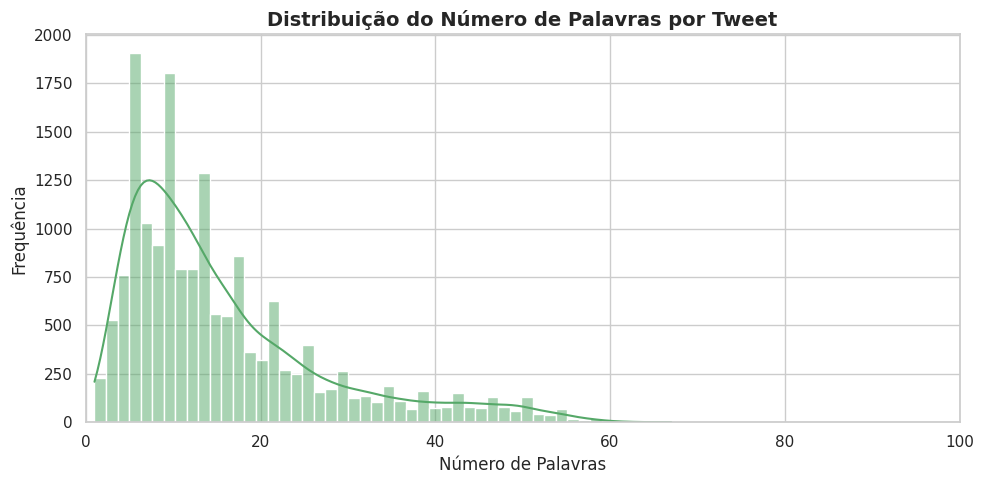

In [8]:
# Calculando o número de palavras por tweet\n",
df_train['num_palavras'] = df_train['text'].apply(lambda x: len(str(x).split()))

print("Estatísticas de Palavras por Tweet (Treino):")
print(df_train['num_palavras'].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df_train['num_palavras'], bins=50, kde=True, color='#55A868')
plt.title('Distribuição do Número de Palavras por Tweet', fontsize=14, fontweight='bold')
plt.xlabel('Número de Palavras')
plt.ylabel('Frequência')
plt.xlim(0, 100) # Limitando o eixo X para melhor visualização (a maioria tem menos de 100)
plt.tight_layout()
plt.savefig('../results/figures/01_comprimento_textos.png', dpi=300)
plt.show()

## 4. Palavras Mais Frequentes (Nuvem de Palavras)\n",

Para entender o vocabulário, vamos separar os tweets tóxicos dos não tóxicos e ver quais palavras dominam em cada grupo. Usaremos a versão limpa do texto (se o `preprocessing.py` já tiver sido rodado).

Usando a coluna: 'text_tfidf' para análise de frequência.


/tmp/ipykernel_12574/333514042.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frequência', y='Palavra', data=df_freq, palette='viridis')


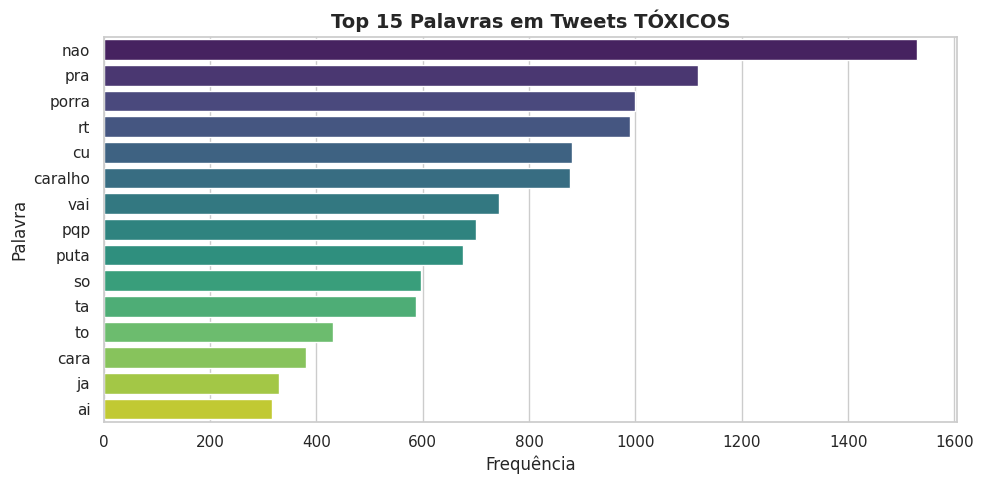

/tmp/ipykernel_12574/333514042.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Frequência', y='Palavra', data=df_freq, palette='viridis')


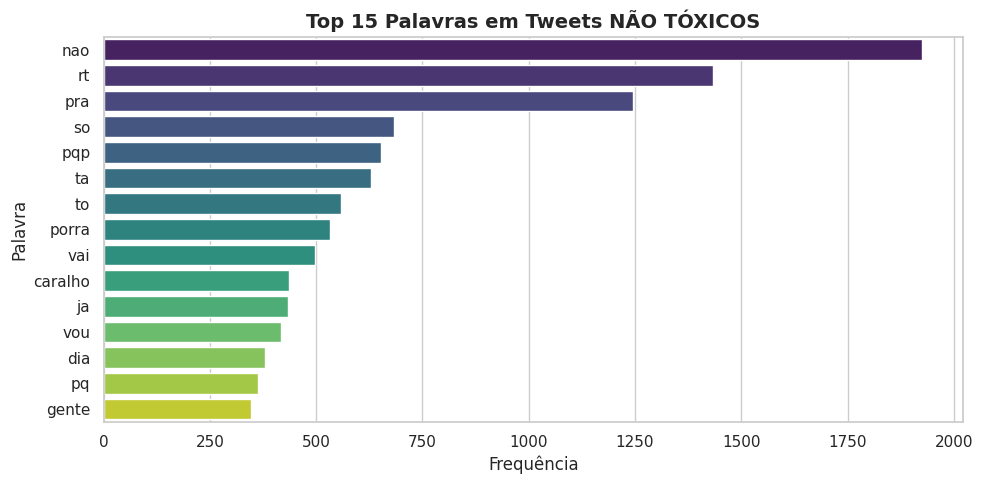

In [9]:
# Verifica se a coluna text_tfidf existe (gerada pelo preprocessing.py)\n",
# Se não existir, usa o texto bruto apenas para esta análise rápida\n",
coluna_texto = 'text_tfidf' if 'text_tfidf' in df_train.columns else 'text'
print(f"Usando a coluna: '{coluna_texto}' para análise de frequência.")

from sklearn.feature_extraction.text import CountVectorizer

def plot_top_ngrams(corpus, title, n=15):
    vec = CountVectorizer(ngram_range=(1, 1), stop_words=None).fit(corpus)
    bag_of_words = vec.transform(corpus)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key = lambda x: x[1], reverse=True)[:n]

    df_freq = pd.DataFrame(words_freq, columns=['Palavra', 'Frequência'])

    plt.figure(figsize=(10, 5))
    sns.barplot(x='Frequência', y='Palavra', data=df_freq, palette='viridis')
    plt.title(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Top 15 palavras em tweets TÓXICOS
textos_toxicos = df_train[df_train['label'] == 1][coluna_texto].dropna().astype(str)
plot_top_ngrams(textos_toxicos, 'Top 15 Palavras em Tweets TÓXICOS')

# Top 15 palavras em tweets NÃO TÓXICOS
textos_nao_toxicos = df_train[df_train['label'] == 0][coluna_texto].dropna().astype(str)
plot_top_ngrams(textos_nao_toxicos, 'Top 15 Palavras em Tweets NÃO TÓXICOS')

# Exportação dos resultados

In [ ]:
import shutil
from google.colab import files

# Cria a pasta se não existir\n",
ensure_dir('../results/figures')

# Compacta as figuras\n",
archive_path = shutil.make_archive("/content/figuras_exploracao", "zip", "../results/figures")
print(f"Arquivo compactado: {archive_path}")

# Inicia o download
files.download(archive_path)

Arquivo compactado: /content/figuras_exploracao.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>